In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import gridspec
from data_setup import RotatedMNIST, create_dataloaders
from model import MultiTaskDNN
import time

## Testing Grounds

Running Data Setup Sanity Check...


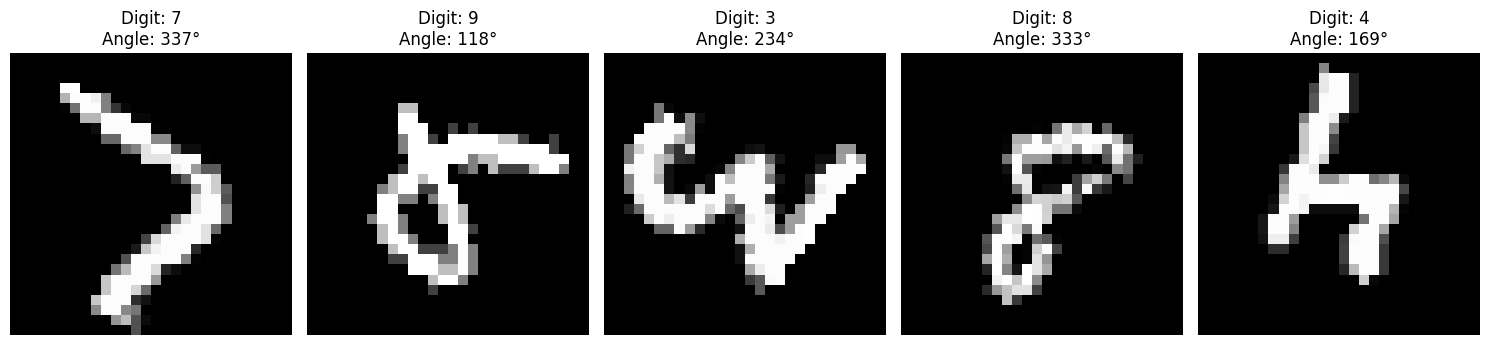

In [2]:
# 1. Create a mock config to test the pipeline locally
mock_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

print("Running Data Setup Sanity Check...")

# 2. Get the dataloaders
train_loader, _ = create_dataloaders(mock_data_cfg)

# 3. Grab a single batch from the training loader
images, digits, angle_rad, angle_deg = next(iter(train_loader))

# 4. Set up the matplotlib figure
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    # Extract the image and remove the channel dimension [1, 28, 28] -> [28, 28]
    img = images[i].squeeze().numpy()

    # Extract values for this particular image
    digit = digits[i].item()
    angle = angle_deg[i].item()

    # Plot the image and set the title
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Digit: {digit}\nAngle: {angle:.0f}°")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [3]:
print("Running Model Architecture Sanity Check...")

mock_model_cfg = {
    'input_shape': 784,
    'shared_layers': 2,
    'task_layers': 2,
    'shared_nodes': 16,
    'task_nodes': 16,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

mock_train_cfg = {
    'activation': 'relu'
}

# Initialize model
mock_model = MultiTaskDNN(mock_model_cfg, mock_train_cfg)

# Create a dummy batch of 5 images (28x28)
dummy_input = torch.randn(5, 1, 28, 28)

# Pass through the model
digit_preds, oddeven_preds, rot_preds, acts = mock_model(dummy_input)

print(f"Model successfully processed dummy batch of shape {dummy_input.shape}")
print(f"Digit Output Shape: {digit_preds.shape} (Expected: 5, 10)")
print(f"Odd/Even Output Shape: {oddeven_preds.shape} (Expected: 5, 2)")
print(f"Rotation Output Shape: {rot_preds.shape} (Expected: 5, 1)")

print("\nTracked Activations:")
for key, tensor in acts.items():
    print(f"  {key}: shape {tensor.shape}")

Running Model Architecture Sanity Check...
Model successfully processed dummy batch of shape torch.Size([5, 1, 28, 28])
Digit Output Shape: torch.Size([5, 10]) (Expected: 5, 10)
Odd/Even Output Shape: torch.Size([5, 2]) (Expected: 5, 2)
Rotation Output Shape: torch.Size([5, 1]) (Expected: 5, 1)

Tracked Activations:
  Shared_Layer_0: shape torch.Size([5, 16])
  Shared_Layer_1: shape torch.Size([5, 16])
  Digit_Layer_0: shape torch.Size([5, 16])
  Digit_Layer_1: shape torch.Size([5, 16])
  Parity_Layer_0: shape torch.Size([5, 16])
  Parity_Layer_1: shape torch.Size([5, 16])
  Rotation_Layer_0: shape torch.Size([5, 16])
  Rotation_Layer_1: shape torch.Size([5, 16])


## Training

In [4]:
# Training configs
training_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

training_model_cfg = {
    'input_shape': 784,
    'shared_layers': 3,
    'task_layers': 3,
    'shared_nodes': 64,
    'task_nodes': 32,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

train_cfg = {
    'activation': 'relu'
}

In [7]:
# Full training routine
train_loader, test_loader = create_dataloaders(training_data_cfg)
training_model = MultiTaskDNN(training_model_cfg, train_cfg)

# Loss functions for each head
digit_loss = nn.CrossEntropyLoss()
parity_loss = nn.CrossEntropyLoss()
def angle_loss(pred, target):
    # Match [B] shapes and measure the shortest signed angular difference.
    diff = pred.squeeze(-1) - target
    circular_diff = torch.atan2(torch.sin(diff), torch.cos(diff))
    return circular_diff.square().mean()
optimizer = torch.optim.Adam(training_model.parameters(), lr=1e-5)

training_model.train()
# Set number of epochs here!
epochs = 2000

epoch_losses = {"full_losses": [], "digit_losses": [], "parity_losses": [], "rotation_losses": []}
print("Start of training!")
start = time.time()
for epoch in range(epochs):
    # Reset epoch loss
    epoch_loss = 0.0
    epoch_digit_loss, epoch_parity_loss, epoch_rot_loss = 0.0, 0.0, 0.0
    
    for images, digits, angle_rad, angle_deg in train_loader:
        # Reset gradients
        optimizer.zero_grad()
        # Determine parity labels
        parity = digits % 2

        # Make predictions
        digit_preds, parity_preds, rot_preds, acts = training_model(images)

        # Assess loss on each head, then sum together
        l_digit = digit_loss(digit_preds, digits)
        l_parity = parity_loss(parity_preds, parity)
        l_rot = angle_loss(rot_preds, angle_rad)

        full_loss = l_digit + l_parity + l_rot
        
        # Make gradient step backwards
        full_loss.backward()
        optimizer.step()

        # Record losses
        epoch_loss += full_loss.item()
        epoch_digit_loss += l_digit.item()
        epoch_parity_loss += l_parity.item()
        epoch_rot_loss += l_rot.item()

    # At end of each epoch, record average batch losses
    avg_loss = epoch_loss / len(train_loader)
    avg_digit_loss = epoch_digit_loss / len(train_loader)
    avg_parity_loss = epoch_parity_loss / len(train_loader)
    avg_rot_loss = epoch_rot_loss / len(train_loader)

    epoch_losses["full_losses"].append(avg_loss)
    epoch_losses["digit_losses"].append(avg_digit_loss)
    epoch_losses["parity_losses"].append(avg_parity_loss)
    epoch_losses["rotation_losses"].append(avg_rot_loss)

    # Save model every 100 epochs, or early models
    if (epoch+1) in [25, 50] or (epoch+1) % 100 == 0:
        torch.save(training_model.state_dict(), f"wide-models/wide-{epoch+1}-epoch-model.pkl")
        min_elapsed = (time.time() - start) / 60
        print(f"   epoch {epoch+1}: avg batch loss {avg_loss:.4f}"
              f"   (digit {avg_digit_loss:.4f}, parity {avg_parity_loss:.4f}, rot {avg_rot_loss:.4f}) [time = {min_elapsed:.2f} min]")
print("End of training!")

Start of training!
   epoch 25: avg batch loss 1.8488   (digit 1.0755, parity 0.3521, rot 0.4212) [time = 8.38 min]
   epoch 50: avg batch loss 1.3827   (digit 0.7662, parity 0.2814, rot 0.3351) [time = 16.76 min]
   epoch 100: avg batch loss 1.1201   (digit 0.5973, parity 0.2340, rot 0.2888) [time = 33.51 min]
   epoch 200: avg batch loss 0.9271   (digit 0.4881, parity 0.1985, rot 0.2404) [time = 67.05 min]
   epoch 300: avg batch loss 0.8534   (digit 0.4443, parity 0.1826, rot 0.2265) [time = 99.27 min]
   epoch 400: avg batch loss 0.8004   (digit 0.4100, parity 0.1753, rot 0.2151) [time = 130.18 min]
   epoch 500: avg batch loss 0.7640   (digit 0.3882, parity 0.1672, rot 0.2085) [time = 160.96 min]
   epoch 600: avg batch loss 0.7357   (digit 0.3685, parity 0.1591, rot 0.2081) [time = 191.80 min]
   epoch 700: avg batch loss 0.7122   (digit 0.3568, parity 0.1541, rot 0.2012) [time = 222.58 min]
   epoch 800: avg batch loss 0.6970   (digit 0.3497, parity 0.1498, rot 0.1974) [time = 2

KeyboardInterrupt: 

In [ ]:
torch.save(training_model.state_dict(), f"wide-models/wide-{epoch+1}-epoch-model.pkl")

## Graphing

In [8]:
# Load model from filepath
def load_DNN_model(filename):
    new_model = MultiTaskDNN(training_model_cfg, train_cfg)
    state_dict = torch.load(filename, map_location="cpu", weights_only=True)
    new_model.load_state_dict(state_dict, strict=True)
    return new_model

# Evaluate model on held-out test data
def evaluate_model(filename):
    model = load_DNN_model(filename)
    
    total_digit_loss, total_parity_loss, total_rot_loss = 0.0, 0.0, 0.0
    total_batches = 0
    model.eval()
    with torch.no_grad():
        for images, digits, angle_rad, angle_deg in test_loader:
            # Determine parity labels
            parity = digits % 2
    
            # Make predictions
            digit_preds, parity_preds, rot_preds, acts = model(images)
            rot_preds = rot_preds.flatten() # Flatten to fit shape from (N, 1) to (N,)
    
            # Accumulate losses
            total_digit_loss += digit_loss(digit_preds, digits).item()
            total_parity_loss += parity_loss(parity_preds, parity).item()
            total_rot_loss += angle_loss(rot_preds, angle_rad).item()
        
            total_batches += 1
    
    avg_total_loss = (total_digit_loss + total_parity_loss + total_rot_loss) / total_batches
    avg_digit_loss = total_digit_loss / total_batches
    avg_parity_loss = total_parity_loss / total_batches
    avg_rot_loss = total_rot_loss / total_batches
    print(f"model path: {filename}")
    print(f"avg test batch loss {avg_total_loss:.4f}"
          f"   (digit {avg_digit_loss:.4f}, parity {avg_parity_loss:.4f}, rot {avg_rot_loss:.4f})")
    return avg_total_loss, avg_digit_loss, avg_parity_loss, avg_rot_loss

In [ ]:
model_val_losses = {}

model_folder = Path("wide-models")
for model_path in model_folder.iterdir():
    if not model_path.suffix == ".pkl":
        continue

    model_epoch = int(str(model_path).split('-')[2])
    avg_total_loss, _, _, _ = evaluate_model(model_path)
    model_val_losses[model_epoch] = avg_total_loss

model_val_losses = {k:v for k, v in sorted(model_val_losses.items(), key=lambda item: item[0])}

model path: wide-models/wide-400-epoch-model.pkl
avg test batch loss 0.5283   (digit 0.2778, parity 0.1204, rot 0.1301)
model path: wide-models/wide-100-epoch-model.pkl
avg test batch loss 0.7718   (digit 0.4260, parity 0.1722, rot 0.1737)
model path: wide-models/wide-500-epoch-model.pkl
avg test batch loss 0.4936   (digit 0.2551, parity 0.1138, rot 0.1246)


In [ ]:
plt.plot(range(len(epoch_losses["full_losses"])), epoch_losses["full_losses"], '-o')
plt.plot(model_val_losses.keys(), model_val_losses.values(), '-o')
plt.title("Epoch Losses")
plt.xlabel("Epoch")
plt.ylabel("Avg Epoch Loss (Digit + Parity + Rotation)")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

new_model.eval()
rot_preds, rot_labels = [], []
digit_preds_all, digit_labels = [], []

with torch.no_grad():
    for images, digits, angle_rad, angle_deg in test_loader:
        digit_pred, _, rot_pred, _ = new_model(images)
        digit_preds_all.append(digit_pred.argmax(dim=1).cpu())
        digit_labels.append(digits.cpu())
        rot_preds.append(rot_pred.cpu())
        rot_labels.append(angle_rad.cpu())
rot_preds_arr = torch.cat(rot_preds).numpy().flatten()
rot_labels_arr = torch.cat(rot_labels).numpy()
cm = confusion_matrix(torch.cat(digit_labels).numpy(),
                      torch.cat(digit_preds_all).numpy(), labels=list(range(10)))

In [ ]:
def angle_loss(pred, target):
    # Match [B] shapes and measure the shortest signed angular difference.
    diff = pred.squeeze(-1) - target
    circular_diff = torch.atan2(torch.sin(diff), torch.cos(diff))
    return circular_diff.square().mean()

In [ ]:
# Rotation plot
rot_preds_arr  = torch.cat(rot_preds).flatten()
digit_labels_arr = torch.cat(digit_labels)
rot_labels_arr = torch.cat(rot_labels)

rot_losses = [angle_loss(rot_pred, rot_label) for (rot_pred, rot_label) in zip(rot_preds_arr, rot_labels_arr)]
rot_losses_arr = np.array(rot_losses)

plt.hist(rot_losses_arr, bins=200)
# Squared circular error is in rad^2; square each radian threshold
for deg, color in [(20, "green"), (45, "yellow"), (90, "orange"), (180, "red")]:
    thresh_loss = angle_loss(torch.tensor([np.deg2rad(deg)]), torch.tensor([0])).item()
    thresh_mean = (rot_losses_arr < thresh_loss).mean()
    plt.axvline(thresh_loss, color=color, linestyle="--", label=f"{deg}° diff. ({thresh_mean:.03f})")

plt.title("Rotation Predictions - Circular Loss")
plt.xlabel("difference (rad^2)")
plt.ylabel("count")
plt.legend()
plt.show()

In [ ]:
rot_preds_arr = torch.cat(rot_preds).flatten()
digit_labels_arr = torch.cat(digit_labels)

x = pd.DataFrame({"rotation_loss": rot_losses_arr, "digit_label": digit_labels_arr})
x.groupby("digit_label").mean().plot(kind='bar')
plt.title("Average rotation loss by digit")
plt.show()

In [ ]:
plt.hist(rot_preds_arr, bins=100)
plt.show()

In [ ]:
# Digit Plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
disp.plot(cmap="Blues", values_format="d")
plt.title("Digit Confusion Matrix")
plt.show()

In [ ]:
overall_acc = cm.trace() / cm.sum()
print(f"Overall accuracy: {overall_acc:.4f}")

## Partial Derivative Maps

In [ ]:
new_model.eval()
images, _, _, _ = next(iter(train_loader))
_, _, _, acts = new_model(images[0:1])
acts.keys()

In [ ]:
# Calculates Jacobian matrix with respect to given layer_name
def jacobian_acts_wrt_input(model, image, layer_name):
    model.eval()  # Use stored batch-normalization statistics for one image.
    if image.ndim == 3:
        image = image.unsqueeze(0)
    if image.ndim != 4 or image.shape[0] != 1:
        raise ValueError("Expected one image with shape [1, H, W] or [1, 1, H, W]")
    image_copy = image.clone().detach().requires_grad_(True)

    def f(x):
        # x: (1, 1, 28, 28) -> (A,)  — recompute inside, from x
        _, _, _, acts = model(x)
        return acts[layer_name].squeeze(0) # (A,)

    jac = torch.autograd.functional.jacobian(f, image_copy)  # (A, 1, 1, 28, 28)
    return jac[:, 0, 0]                         # (A, 28, 28)

In [ ]:
# Helper function that gets the same batches each time
def collect_batches(num_batches):
    # use SequentialSampler to get the same batches each time
    dataset = test_loader.dataset
    sampler = SequentialSampler(dataset)

    loader = DataLoader(dataset, batch_size=test_loader.batch_size,
                        sampler=sampler, num_workers=0)
    
    images_list, digits_list, rots_list = [], [], []
    i = 0
    for images, digits, rad_rots, _ in loader:
        i += 1
        images_list.append(images)
        digits_list.append(digits)
        rots_list.append(rad_rots)
        if i >= num_batches:
            break

    all_images = torch.cat(images_list, dim=0)   # (N, 1, 28, 28)
    all_digits = torch.cat(digits_list, dim=0) # (N,)
    all_rots   = torch.cat(rots_list, dim=0)   # (N,)
    return all_images, all_digits, all_rots

In [ ]:
def plot_jacobians_across_images(model, layer_name, num_samples):
    images, _, _ = collect_batches(5)
    num_samples = min(num_samples, len(images))
    jacobians = []
    
    for i in range(num_samples): # (1, 1, 28, 28)
        image = images[i:i + 1]
        jac = jacobian_acts_wrt_input(model, image, layer_name)
        jacobians.append(jac)
    
    # stack -> (B, A, 28, 28)
    stacked_jacobians = torch.stack(jacobians)
    neuron_count = stacked_jacobians.shape[1]
    
    for i in range(num_samples):
        ncols_act = 8
        nrows_act = int(np.ceil(neuron_count / ncols_act))
        fig = plt.figure(figsize=(2.2 + ncols_act * 1.5, nrows_act * 1.5))
    
        outer = gridspec.GridSpec(
            1, 2, figure=fig,
            width_ratios=[1, ncols_act],   # input is 1 "cell" wide, acts are ncols_act
            wspace=0.05,
        )
    
        # --- left: original image ---
        ax_in = fig.add_subplot(outer[0])
        ax_in.imshow(images[i, 0].cpu(), cmap="gray")
        ax_in.set_title("input"); ax_in.axis("off")
    
        # --- right: nested grid of activations ---
        inner = gridspec.GridSpecFromSubplotSpec(
            nrows_act, ncols_act, subplot_spec=outer[1],
            wspace=0.05, hspace=0.05,
        )
        im = None
        vmax = stacked_jacobians[i].abs().max().item() # recalculate vmax for each image
        for j in range(neuron_count):
            r, c = divmod(j, ncols_act)
            ax = fig.add_subplot(inner[r, c])
            im = ax.imshow(stacked_jacobians[i, j], cmap="RdBu_r",
                           vmin=-vmax, vmax=vmax)
            ax.set_title(f"a{j}", fontsize=6, pad=1)
            ax.axis("off")
    
        fig.colorbar(im, ax=fig.axes, fraction=0.02, pad=0.01,
                     label="Partial derivative (∂a/∂x)")
        fig.suptitle(f"{layer_name} - sample {i+1}", y=1.02)
        plt.show()

In [ ]:
def plot_jacobians_across_layers(model, layer_names, image_idx=0):
    images, _, _ = collect_batches(3)
    image = images[image_idx:image_idx + 1]        # (1, 1, 28, 28)

    # compute per layer
    for layer_name in layer_names:
        jac = jacobian_acts_wrt_input(model, image, layer_name)   # (A, 28, 28)
        stacked = jac.cpu().numpy()                               # (A, 28, 28)
        vmax = jac.abs().max().item()

        # one figure per layer 
        neuron_count = stacked.shape[0]
        ncols_act    = 8
        nrows_act    = int(np.ceil(neuron_count / ncols_act))

        fig = plt.figure(figsize=(2.2 + ncols_act * 1.5, nrows_act * 1.5))

        outer = gridspec.GridSpec(
            1, 2, figure=fig,
            width_ratios=[1, ncols_act], wspace=0.05,
        )

        # left: original image (same every figure)
        ax_in = fig.add_subplot(outer[0])
        ax_in.imshow(image[0, 0].cpu(), cmap="gray")
        ax_in.set_title("input"); ax_in.axis("off")

        # right: nested grid
        inner = gridspec.GridSpecFromSubplotSpec(
            nrows_act, ncols_act, subplot_spec=outer[1],
            wspace=0.05, hspace=0.05,
        )
        mosaic_axes = []
        im = None
        for j in range(neuron_count):
            r, c = divmod(j, ncols_act)
            ax = fig.add_subplot(inner[r, c])
            im = ax.imshow(stacked[j], cmap="RdBu_r",
                           vmin=-vmax, vmax=vmax)
            ax.set_title(f"a{j}", fontsize=6, pad=1)
            ax.axis("off")
            mosaic_axes.append(ax)

        fig.colorbar(im, ax=mosaic_axes, fraction=0.02, pad=0.01,
                     label="Partial derivative (∂a/∂x)")
        fig.suptitle(f"{layer_name} — sample {image_idx+1}", y=1.02)
        plt.show()

In [ ]:
layer_names = ["Rotation_Layer_0", "Rotation_Layer_4"]

for i in range(2):
    plot_jacobians_across_layers(new_model, layer_names, image_idx=i+2)

In [ ]:
acts.keys()

In [ ]:
layer_name = "Shared_Layer_0"
num_samples = 4

plot_jacobians_across_images(new_model, layer_name, num_samples)

In [ ]:
plot_jacobians_across_images(new_model, "Rotation_Layer_4", num_samples)

In [ ]:
def plot_jacobian_tunings(model, layer_name, num_batches):
    jacobians, sampled_digits = [], []
    if num_batches < 1:
        raise ValueError("num_batches must be positive")

    for batch_idx, (images, digits, _, _) in enumerate(train_loader):
        for i in range(len(images)):
            jac = jacobian_acts_wrt_input(model, images[i:i + 1], layer_name)
            jacobians.append(jac)
        sampled_digits.append(digits)
        if batch_idx + 1 >= num_batches:
            break

    # stack -> (B, A, 28, 28)
    stacked_jacobians = torch.stack(jacobians)
    sampled_digits = torch.cat(sampled_digits)
    neuron_count = stacked_jacobians.shape[1]
    all_digit_tunings = []
    for neuron_idx in range(neuron_count):
        digit_tunings = []
        for digit in range(10):
            mask = sampled_digits == digit
            # Missing digits have no estimated tuning, rather than zero sensitivity.
            tuning = (stacked_jacobians[mask, neuron_idx].abs().mean().item()
                      if mask.any() else float('nan'))
            digit_tunings.append(tuning)
        print(digit_tunings)
        all_digit_tunings.append(digit_tunings)
    return all_digit_tunings

plot_jacobian_tunings(new_model, "Rotation_Layer_0", 1)


In [ ]:
def plot_jacobian_tunings(model, layer_name, num_batches, n_bins=12, figsize=(11, 4)):
    all_images, all_digits, all_rots = collect_batches(num_batches)

    jacobians = []
    for image in all_images:
        jac = jacobian_acts_wrt_input(model, image, layer_name)
        jacobians.append(jac)
    
    # stack -> (B, A, 28, 28)
    stacked_jacobians = torch.stack(jacobians)
    neuron_count = stacked_jacobians.shape[1]

    #collapse each (28,28) map to a scalar per (image, neuron)
    # mean |∂a/∂x| — how strongly the input pixels influence this neuron
    energy = stacked_jacobians.abs().mean(dim=(2, 3))   # (B, A)

    # digit tuning: mean energy per digit, shape (10, A)
    digit_tuning = torch.zeros(10, neuron_count)
    for d in range(10):
        mask = (all_digits == d)
        if mask.any():
            digit_tuning[d] = energy[mask].mean(dim=0)

    # rotation tuning: bin angles, mean energy per bin
    rot_np   = all_rots.numpy()
    edges    = np.linspace(0, 2 * np.pi, n_bins + 1)
    bin_idx  = np.clip(np.digitize(rot_np, edges) - 1, 0, n_bins - 1)

    rot_tuning = torch.zeros(n_bins, neuron_count)
    for b in range(n_bins):
        mask = torch.from_numpy(bin_idx == b)
        if mask.any():
            rot_tuning[b] = energy[mask].mean(dim=0)

    # per-neuron plots
    for neuron_idx in range(neuron_count):
        fig, (ax_d, ax_r) = plt.subplots(1, 2, figsize=figsize)

        ax_d.bar(range(10), digit_tuning[:, neuron_idx].numpy())
        ax_d.set_xticks(range(10))
        ax_d.set_xlabel("digit"); ax_d.set_ylabel("mean |∂a/∂x|")
        ax_d.set_title(f"Digit tuning — neuron a{neuron_idx}")

        bin_centers = 0.5 * (edges[:-1] + edges[1:])
        ax_r.bar(bin_centers, rot_tuning[:, neuron_idx].numpy(),
                 width=(bin_centers[1] - bin_centers[0]) * 0.9)
        ax_r.set_xlabel("rotation angle (rad)"); ax_r.set_ylabel("mean |∂a/∂x|")
        ax_r.set_title(f"Rotation tuning — neuron a{neuron_idx}")

        fig.suptitle(f"{layer_name}", y=1.02)
        plt.tight_layout()
        plt.show()

    return stacked_jacobians, digit_tuning, rot_tuning

x = plot_jacobian_tunings(new_model, "Rotation_Layer_0", 5, n_bins=20)

In [ ]:
def plot_jacobian_digit_tunings(model, layer_name, num_batches,
                                ncols=4, figsize=None):
    all_images, all_digits, all_rots = collect_batches(num_batches)

    # --- compute jacobians per image ---
    jacobians = []
    for i in range(all_images.shape[0]):
        jac = jacobian_acts_wrt_input(model, all_images[i:i+1], layer_name)
        if jac.dim() == 4:                # tolerate (A, 1, 28, 28)
            jac = jac.squeeze(1)
        jacobians.append(jac.detach().cpu())

    stacked_jacobians = torch.stack(jacobians)        # (B, A, 28, 28)
    neuron_count = stacked_jacobians.shape[1]

    # --- scalar per (image, neuron) ---
    energy = stacked_jacobians.abs().mean(dim=(2, 3))  # (B, A)

    # --- digit tuning: shape (10, A) ---
    digit_tuning = torch.zeros(10, neuron_count)
    digits_cpu = all_digits.cpu()
    for d in range(10):
        mask = digits_cpu == d
        if mask.any():
            digit_tuning[d] = energy[mask].mean(dim=0)

    # --- one figure with a panel per neuron ---
    nrows = int(np.ceil(neuron_count / ncols))
    if figsize is None:
        figsize = (ncols * 3.2, nrows * 2.6)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize,
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    digit_pos = np.arange(10)
    ymax = digit_tuning.max().item() if digit_tuning.numel() else 1.0

    for neuron_idx in range(neuron_count):
        ax = axes[neuron_idx]
        ax.bar(digit_pos, digit_tuning[:, neuron_idx].numpy(),
               color="steelblue")
        ax.set_title(f"a{neuron_idx}", fontsize=9)
        ax.set_ylim(0, ymax * 1.05)
        ax.set_xticks(digit_pos)
        ax.grid(True, alpha=0.3)

    # hide any unused panels
    for ax in axes[neuron_count:]:
        ax.axis("off")

    # shared axis labels — bottom row for x, left column for y
    for ax in axes[-ncols:]:
        if ax.get_visible():
            ax.set_xlabel("digit")
    for r in range(nrows):
        axes[r * ncols].set_ylabel("mean |∂a/∂x|")

    fig.suptitle(f"Digit tuning per neuron — {layer_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    return stacked_jacobians, digit_tuning

In [ ]:
x = plot_jacobian_digit_tunings(new_model, "Digit_Layer_0", 10)

In [ ]:
x = plot_jacobian_digit_tunings(new_model, "Digit_Layer_4", 10)

In [ ]:
def plot_jacobian_rot_tunings(model, layer_name, num_batches, n_bins=12,
                              ncols=4, figsize=None):
    all_images, all_digits, all_rots = collect_batches(num_batches)

    # --- compute jacobians per image ---
    jacobians = []
    for i in range(all_images.shape[0]):
        jac = jacobian_acts_wrt_input(model, all_images[i:i+1], layer_name)
        if jac.dim() == 4:                # tolerate (A, 1, 28, 28)
            jac = jac.squeeze(1)
        jacobians.append(jac.detach().cpu())

    stacked_jacobians = torch.stack(jacobians)        # (B, A, 28, 28)
    neuron_count = stacked_jacobians.shape[1]

    # --- scalar per (image, neuron) ---
    energy = stacked_jacobians.abs().mean(dim=(2, 3))  # (B, A)

    # --- rotation binning ---
    rot_np  = all_rots.cpu().numpy()
    edges   = np.linspace(0, 2 * np.pi, n_bins + 1)
    bin_idx = np.clip(np.digitize(rot_np, edges) - 1, 0, n_bins - 1)

    # --- rot tuning: shape (n_bins, A) ---
    rot_tuning = torch.zeros(n_bins, neuron_count)
    for b in range(n_bins):
        mask = torch.from_numpy(bin_idx == b)
        if mask.any():
            rot_tuning[b] = energy[mask].mean(dim=0)

    # --- one figure with a panel per neuron ---
    nrows  = int(np.ceil(neuron_count / ncols))
    if figsize is None:
        figsize = (ncols * 3.2, nrows * 2.6)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize,
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    bin_centers = 0.5 * (edges[:-1] + edges[1:])
    bin_width   = (bin_centers[1] - bin_centers[0]) * 0.9

    # per-neuron bar heights go on one shared scale so panels are comparable
    ymax = rot_tuning.max().item() if rot_tuning.numel() else 1.0

    for neuron_idx in range(neuron_count):
        ax = axes[neuron_idx]
        ax.bar(bin_centers, rot_tuning[:, neuron_idx].numpy(),
               width=bin_width, color="steelblue")
        ax.set_title(f"a{neuron_idx}", fontsize=9)
        ax.set_ylim(0, ymax * 1.05)
        ax.grid(True, alpha=0.3)

    # hide any unused panels
    for ax in axes[neuron_count:]:
        ax.axis("off")

    # shared axis labels — put on the bottom row / left column only
    for ax in axes[neuron_count:neuron_count + ncols]:
        if ax.get_visible():
            ax.set_xlabel("rotation (rad)")
    for r in range(nrows):
        axes[r * ncols].set_ylabel("mean |∂a/∂x|")

    fig.suptitle(f"Rotation tuning per neuron — {layer_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    return stacked_jacobians, rot_tuning

In [ ]:
x = plot_jacobian_rot_tunings(new_model, "Digit_Layer_0", 10, n_bins=20)

In [ ]:
x = plot_jacobian_rot_tunings(new_model, "Digit_Layer_4", 10, n_bins=20)